# Lab 5: Introduction to Medical Imaging
***
## Section 0: Intro to MRI
### Motivation
Medical imaging lets us see inside the human body without surgery, which is great! However, turning measurements into a useful image takes some serious engineering. In this lab, we will seek to answer the following question: 

$$ \text{How does an engineer design measurement schemes under the constraints imposed by an imaging modality?} $$

For example, the imaging technique we will discuss in this lab, **M**edical **R**esonance **I**maging (MRI), without alteration, can require patients to be very still for prolonged periods of time which may not be possible (e.g. energetic children, elderly people with stiff backs, etc). Our goals are as follows:

1. Use the data measured by an MRI Scanner to reconstruct a clear, medical-grade image 
2. Design MRI measurement schemes that reduce the time & stillness required to produce clear, medical-grade images  

***
That being said, here's what we'll be learning today:
### Learning Objectives
By engaging actively with this lab, students will make progress towards being able to:
1. Read the k-space of an MRI measurement, and in doing so: 
    <ol type="a">
        <li>Understand what a k-space's low and high frequencies encode in the original image</li>
       <li>Understand how different k-space sampling patterns reconstruct images with different resolutions and field of views from the same k-space</li>
    </ol> 
2. Design k-space sampling patterns, and in doing so: 
    <ol type="a">
        <li>Use zero-fill and <b>B</b>asis <b>P</b>ursuit <b>D</b>enoising (BPD) to reconstruct images from a limited amount of k-space</li>
       <li>Use different k-space sampling patterns to reduce MRI measurement motion artifacts in reconstructed images</li>
    </ol> 
3. Build an MRI operator to distinguish measurement agreement from image accuracy

***
### What is MRI & How Does it Work? 

At a high level, MRI is an imaging modality. This means that MRI produces an image of a patient by transmitting energy _into_ the patient and then receiving energy _from_ the patient. Figuring out the right way to deposit and detect this energy is a tough interdisciplinary engineering challenge regardless of the imaging modality.

At a low level, MRI uses a strong uniform magnetic field and radio-frequency excitation fields to make the hydrogen nuclei in your body (e.g. water) spin. Then, non-uniform gradient fields give the spins' precession frequency a spatial dependence. The received signal depends on this resonant frequency; we use that spatial dependence to reconstruct an image. Note that MRI **does not** use ionizing radiation (X-rays), and the signal ultimately comes from the precessing nuclei themselves.

For the purposes of this lab, the most important part about MRI is that MRI gives us the k-space (2D DTFS coefficients) of an image/patient which we can use to reconstruct a picture of what's inside the human body!

**Note:** What we will learn regarding k-spaces applies to ANY k-space (ANY set of 2D DTFS coefficients) regardless of if it originated from an MRI Scanner. For example, this means that if we decompose a 1920 pixel by 1080 pixel image into its k-space by taking its 2D DFT, we can apply the following techniques we will learn to reconstruct the original image from a partial k-space!

<p align="center">
  <img src="lab_assets/mri.jpg" width="500" alt="MRI Scanner">
</p>

***
### DTFS, DFT, IDFT, FFT, and IFFT!
Because these topics appear all over this lab and are closely related (yet distinct), we will define them here:

**Discrete-Time Fourier Series (DTFS)**: The DTFS of a DT signal ($x[n]$) is the linear combination of complex exponential frequencies ($\psi_k[n]=e^{ikw_0n}$) that represent the DT signal. The DT signal being decomposed may not be 1D. Accordingly, the complex exponential frequencies may not be 1D either.

$$ \text{Example of DTFS: } x[n] = cos(\pi n) = 1*\psi_1[n] = e^{i1w_0n} = e^{i\pi n} \qquad \text{where } w_0 = \frac{2\pi}{p} = \frac{2\pi}{2} = \pi$$

**Discrete Fourier Transform (DFT)**: When you take the DFT of a DT signal, you are applying the Analysis equation (*see below*) on that signal to retreive its DTFS coefficients (the $X_k's$). The DT signal being decomposed may not be 1D. BEWARE: Sometimes people drop the "Discrete" part and just say "Fourier Transform."

$$ \text{ Analysis Equation: } X_k = \frac{1}{p}\sum_{<p>} x[n] * e^{ikw_on} \qquad \text{where } w_0 = \frac{2\pi}{p} $$

**Inverse Discrete Fourier Transform** (IDFT): When you take the IDFT of a DT signal's DTFS coefficients, you are applying the Synthesis equation (*see below*) on that signal's DTFS coefficients (the $X_k's$) to retreive the signal itself ($x[n]$). The DT signal being reconstructed may not be 1D. BEWARE: Sometimes people drop the "Discrete" part and just say "Inverse Fourier Transform."

$$ \text{ Synthesis Equation: } x[n] = \sum_{<p>} X_k * e^{-ikw_on} \qquad \text{where } w_0 = \frac{2\pi}{p} $$

**Fast Fourier Transform (FFT)**: A particularly fast algorithm for taking the DFT of a DT signal (i.e. a fast algorithm for finding the DTFS coefficients of a DT signal). The DT signal may not be 1D.

**Inverse Fast Fourier Transform (IFFT)**: A particularly fast algorithm for taking the IDFT of a DT signal's DTFS coefficients. The DT signal may not be 1D.



***
### Getting Started
First, run the cell below to import all the Python packages/modules necessary for this lab!

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import ipywidgets as widgets
import inspect
import collections
import IPython.display

from lab_tools import *
from lab_impl import *

Each cell which requires you to implement a solution will say ```"*** YOUR CODE HERE ***"```. After you have a solution you are happy with, run the test cell below your solution's cell to test your code!

***
## Section 1: MRI Extravaganza!
### Chapter 1: The Importance of Sampling Rate (feat. 1D Signals)
A scanner -- acoustic, MRI, or otherwise -- only has finite time, so it cannot measure an infinitely-long CT signal nor sample arbitrarily densely. Sampling too coarsely (not frequent enough) makes different frequencies produce indistinguishable sample values. This is called **aliasing**, and it is the same phenomenon you will see again later in this lab when working with 2D signals.

The signal plotted below is

$$f(t) = \sin(2\pi \cdot 7\,t) + 0.55\,\sin(2\pi \cdot 33\,t) \qquad 0 \le t < 1,$$

a 7 Hz sinusoid plus a smaller 33 Hz sinusoid, over one second. The **gray curve** is the continuous signal; the **orange lollipops** are the samples we would actually measure with 24, 48, and 96 evenly spaced samples.

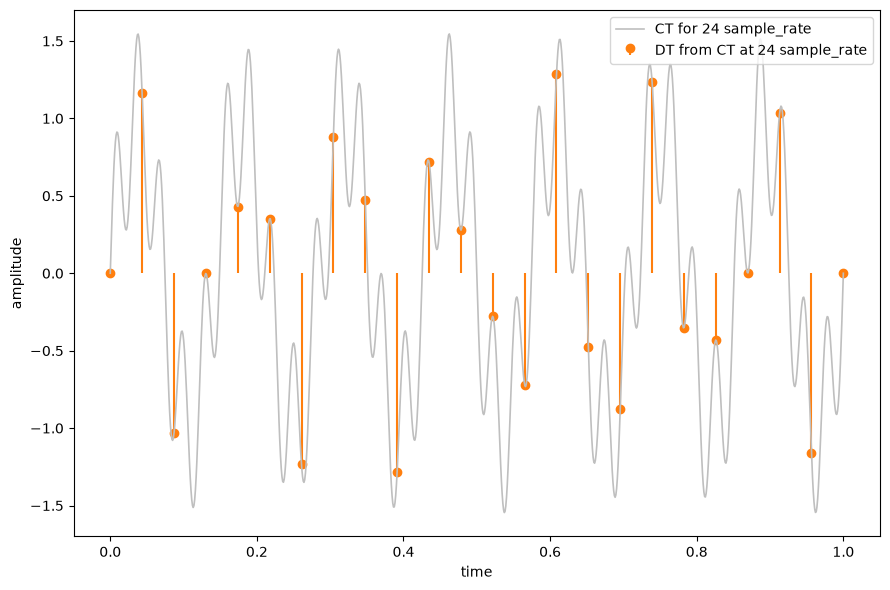

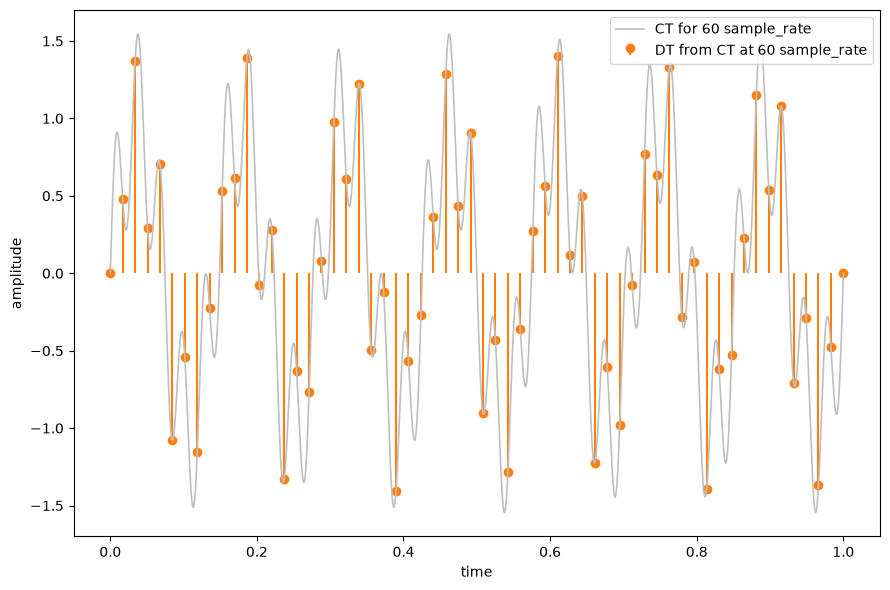

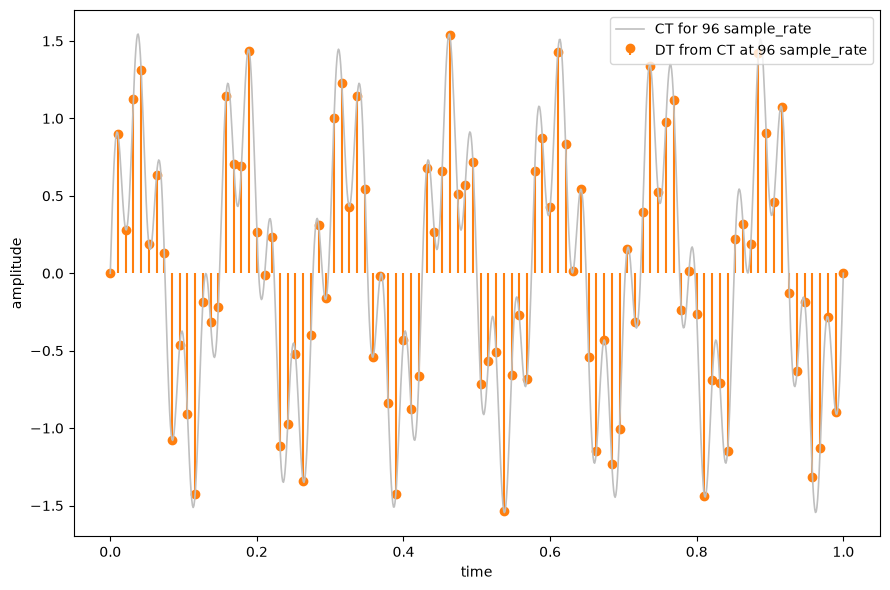

In [2]:
def f(t: float) -> float:
    freq_low = 7
    freq_high = 33
    return np.sin(2*np.pi*freq_low*t) + 0.55*np.sin(2*np.pi*freq_high*t)

sample_rates = [24, 60, 96]
for sr in sample_rates:
    show_signal(DTSignalFromCTSignalAndCTSignal(f, DTSignal.DEFAULT_STEM, CTSignal.DEFAULT_PLOT, sr), 0, 1)

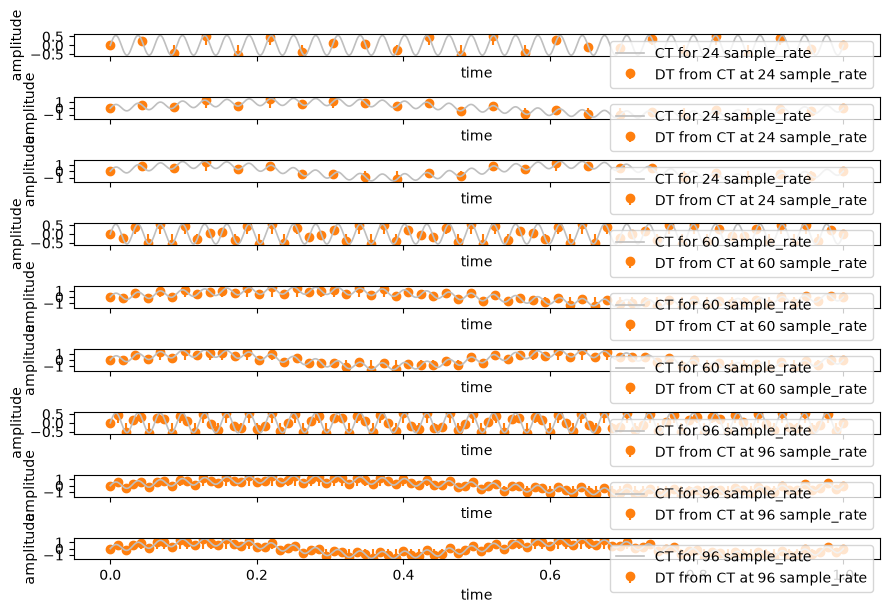

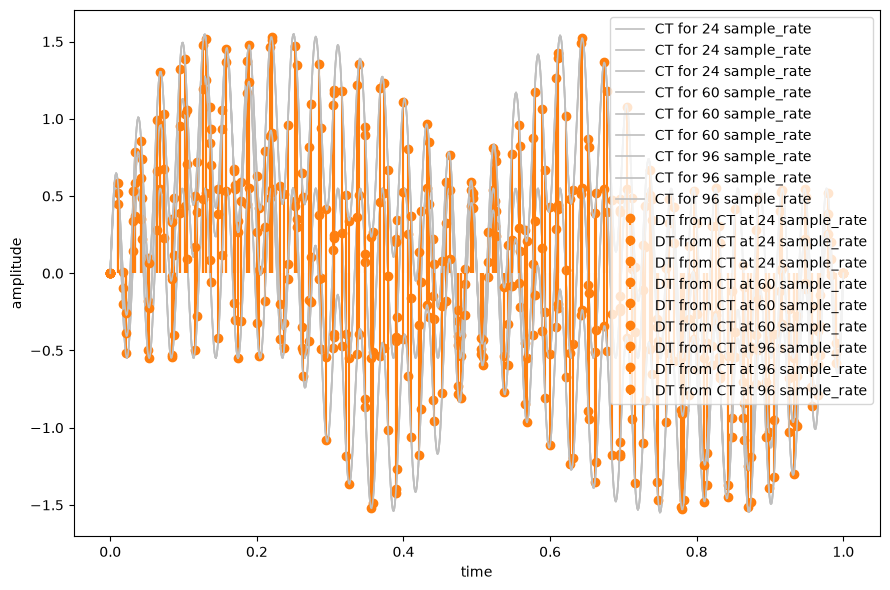

In [8]:
def h(freq_low):
    freq_high = 33
    return lambda t: np.sin(2*np.pi*freq_low*t) + 0.55*np.sin(2*np.pi*freq_high*t)

sample_rates = [24, 60, 96]
signal_list = []
for sr in sample_rates:
    for freq_low in range(0, 3):
        signal_list.append(DTSignalFromCTSignalAndCTSignal(h(freq_low), DTSignal.DEFAULT_STEM, CTSignal.DEFAULT_PLOT, sr))

show_many_signals(signal_list, 0, 1)
show_many_overlapped_signals(signal_list, 0, 1)

**Conceptual Check 1.1:** 
1. Looking at the plot above, what is the issue with the 24-sample row? 
2. Which of the two sinusoids (7Hz or 33Hz) do you expect to be reconstructed incorrectly, and why? 


Replace This Text With Your Response!

The main takeaway from above is that **sampling too far apart (i.e. too slowly) can cause us to lose valuable information**, a phenomenon known as *aliasing*.

If you take EE120, you'll explore this idea more formally through the *Nyquist rate*.

Another fundamental relationship you'll explore later in 2D is between **sampling extent** and **resolution**.

- **Sampling extent** is how much of a domain we measure. In time, it's the length of the recording ($T$ seconds in the example below). In k-space, it's how far out from the center we collect samples.
- **Resolution** refers to how finely we can distinguish nearby structures in the other (Fourier-transformed) domain.

Sampling over a larger extent in one domain lets us resolve finer details in the other.

For now, we'll demonstrate this by sampling a signal in the time domain and examining its frequency resolution using the DFT. We'll define a simple sum of sinusoids below and, just for fun, add a small bit of noise. Then, we take the fourier transform and see how it looks. The signal is

$$g(t) = 2.8\,\sin(2\pi \cdot 1\,t) + 0.4\,\sin(2\pi \cdot 0.5\,t) + 1.2\,\sin(2\pi \cdot 2\,t) + \text{noise}, \qquad 0 \le t < T,$$

so it contains sinusoids at 0.5 Hz, 1 Hz, and 2 Hz. The slider sets $T$, the sampling extent in seconds (the sampling *rate* stays fixed at 1000 samples per second). Start with $T = 1$.

In [4]:
def draw_freq_plt(T):
    n_samples = int(T*1000)  # keep sampling rate identical

    t = np.linspace(0, T, n_samples)
    f = 2.8*np.sin(2*np.pi*t) + 0.4*np.sin(0.5 * 2*np.pi*t) + 1.2*np.sin(2 * 2*np.pi*t) + np.random.randn(n_samples)
    
    _F = np.fft.fft(np.pad(f, (0, 10*n_samples)))    # zero padding gives smoother frequency representation but NO REAL CHANGE IN RESOLUTION
    _freqs = np.fft.fftfreq(_F.shape[0], d=T/n_samples)
    _F = _F[:_F.shape[0]//256]                 # plot only the lowest frequencies for the purposes of demonstration
    _freqs = _freqs[:_freqs.shape[0]//256]
    plt.figure()
    plt.plot(_freqs, np.abs(_F))
    plt.tick_params(left=False, labelleft=False)
    plt.xlabel("frequency (Hz)")
    plt.gca()

slidered(draw_freq_plt, {}, slider = widgets.FloatSlider(
    value=7.5,
    min=0.01,
    max=10.0,
    step=0.1,
    description="T: ",
    continuous_update=True,
    orientation="horizontal",
    readout=True,
    readout_format=".1f",
))

interactive(children=(FloatSlider(value=7.5, description='T: ', max=10.0, min=0.01, readout_format='.1f'), Out…

If the result does not match your expectations, try sampling with a greater extent by moving the slider!

**Conceptual Check 1.2:** 
1. What is the smallest extent with which you can sample and resolve the spikes? A rough estimate is fine.

Replace This Text With Your Response!

### Chapter 2: 2D Fourier Transforms (feat. 2D Signals)

In Section 0, we wrote a 1D signal as a sum of sinusoids. Images work the same way, except the building blocks are **2D sinusoids**, which look like stripes across the image. Together, patterns like these form the **2D Fourier basis**, and a few of them are plotted below.

Each pattern is labeled by two frequencies $(k_x, k_y)$, where $k_x$ is how many times the pattern repeats as you move left to right across the image, and $k_y$ is how many times it repeats from top to bottom. Larger values give finer stripes, and the mix of $k_x$ and $k_y$ sets which way the stripes are tilted. The pattern $(0, 0)$ is constant and just sets the overall brightness.

## ... SKIPPING TO A CODING QUESTION ...

First, **write the following function** to create a radial boolean mask we could use to keep only frequencies near the center of k-space. The mask is `True` (or 1) at the k-space positions you want to keep and `False` (or 0) everywhere else.

In [5]:
HINTS_FOR_make_radial_mask()

Accordion(children=(HTML(value='Try setting the slider to <b>0</b> or <b>100</b> to test the boundary values.'…

Accordion(children=(HTML(value='Try <b>NOT</b> setting the slider to <b>0</b> or <b>100</b> to test the bounda…

In [6]:
def make_radial_mask(shape: tuple, radius: float):
    """Make a filled circle (disk) mask centered in the image.

    Inputs:
        shape  -- (h, w), the size of the mask (same as the image / k-space)
        radius -- radius of the circle, in pixels

    Returns:
        a boolean array of size (h, w): True inside the circle (distance from
        the center (h/2, w/2) less than `radius`), False everywhere else.

    Why: applied to centered k-space, this keeps only the LOW frequencies.
    """
    yy, xx = np.indices(shape)   # yy[i, j] = i (row index), xx[i, j] = j (column index)
    h, w = shape

    "*** YOUR CODE HERE ***"
    return np.array([])
    

In [7]:
assert np.array_equal(make_radial_mask((3, 3), 1), np.array([[False, False, False], [False, True, False], [False, False, False]])), "FAILED: 3x3 with 1x1 in middle"
assert np.array_equal(make_radial_mask((4, 4), 2), np.array([[False, False, False, False], [False, True, True, False], [False, True, True, False], [False, False, False, False]])), "FAILED: 4x4 with 2x2 in middle" 

AssertionError: FAILED: 3x3 with 1x1 in middle